# Frequency Ratio Landslide Susceptibility Mapping
### Udayapur District, Eastern Nepal – Version 1

This notebook works with the results already generated in ArcGIS.

**Associated Paper:**  
Subedi, P., Devkota, U., Adhikari, S., Baral, D., Adhikari, M., & Joshi, R. (2026).  
Landslide Susceptibility Mapping Using GIS-Based Frequency Ratio Method in Eastern Nepal.  
*Applied and Environmental Soil Science*, 2026, Article 6678592.  
https://doi.org/10.1155/aess/6678592

**Note:** Full Frequency Ratio recalculation in pure Python will be added in a future version.

In [2]:
# ================================
# Check and Install Required Libraries
# ================================

import subprocess
import sys

required_libraries = [
    "numpy",
    "pandas",
    "geopandas",
    "rasterio",
    "scikit-learn",
    "matplotlib",
    "seaborn",
    "openpyxl",
    "shapely",
    "fiona",
    "pyproj"
]

def install_package(package):
    subprocess.check_call([sys.executable, "-m", "pip", "install", package])

print("Checking required libraries...\n")

for lib in required_libraries:
    try:
        __import__(lib if lib != "scikit-learn" else "sklearn")
        print(f"✓ {lib} is already installed")
    except ImportError:
        print(f"✗ {lib} is missing → Installing...")
        try:
            install_package(lib)
            print(f"  → {lib} installed successfully")
        except Exception as e:
            print(f"  → Failed to install {lib}: {e}")

print("\nLibrary check completed.")

Checking required libraries...

✓ numpy is already installed
✓ pandas is already installed
✓ geopandas is already installed
✓ rasterio is already installed
✓ scikit-learn is already installed
✓ matplotlib is already installed
✓ seaborn is already installed
✓ openpyxl is already installed
✓ shapely is already installed
✗ fiona is missing → Installing...
  → Failed to install fiona: Command '['c:\\Users\\pramo\\AppData\\Local\\Python\\pythoncore-3.14-64\\python.exe', '-m', 'pip', 'install', 'fiona']' returned non-zero exit status 1.
✓ pyproj is already installed

Library check completed.


In [13]:
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.plot import show
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully")

Libraries imported successfully


In [14]:
BASE_DIR = ".."

# Results
LSI_PATH = os.path.join(BASE_DIR, "04_Results", "LSI_Continuous", "LSI_Continuous.tif")
CLASSIFIED_PATH = os.path.join(BASE_DIR, "04_Results", "Classified_5_Classes", "LSI_5_Classes.tif")

# Inventory
TRAIN_PATH = os.path.join(BASE_DIR, "03_Processed_Data", "Inventory", "Training.shp")
TEST_PATH  = os.path.join(BASE_DIR, "03_Processed_Data", "Inventory", "Testing.shp")

# FR Table
FR_PATH = os.path.join(BASE_DIR, "03_Processed_Data", "FR_Tables", "FR.xlsx")

print("Paths set successfully")

Paths set successfully


In [15]:
# Load FR table
fr_df = pd.read_excel(FR_PATH)
print("FR Table loaded. Shape:", fr_df.shape)

# Load training and testing points
train_gdf = gpd.read_file(TRAIN_PATH)
test_gdf  = gpd.read_file(TEST_PATH)

print(f"Training points: {len(train_gdf)}")
print(f"Testing points : {len(test_gdf)}")

FR Table loaded. Shape: (89, 8)
Training points: 146
Testing points : 62


In [16]:
def extract_values(raster_path, gdf):
    """
    Extract raster values at the centroid of each geometry
    (works for both Points and Polygons)
    """
    # Get centroids
    centroids = gdf.geometry.centroid
    coords = [(geom.x, geom.y) for geom in centroids]
    
    with rasterio.open(raster_path) as src:
        values = [val[0] for val in src.sample(coords)]
    
    return np.array(values)

# Extract LSI values
test_lsi = extract_values(LSI_PATH, test_gdf)
train_lsi = extract_values(LSI_PATH, train_gdf)

print("LSI values extracted at landslide locations (using centroids)")
print(f"Testing LSI - Mean: {np.nanmean(test_lsi):.3f}")
print(f"Training LSI - Mean: {np.nanmean(train_lsi):.3f}")
print(f"Testing LSI - Min: {np.nanmin(test_lsi):.3f}, Max: {np.nanmax(test_lsi):.3f}")

LSI values extracted at landslide locations (using centroids)
Testing LSI - Mean: 250.611
Training LSI - Mean: 260.593
Testing LSI - Min: 183.100, Max: 468.850


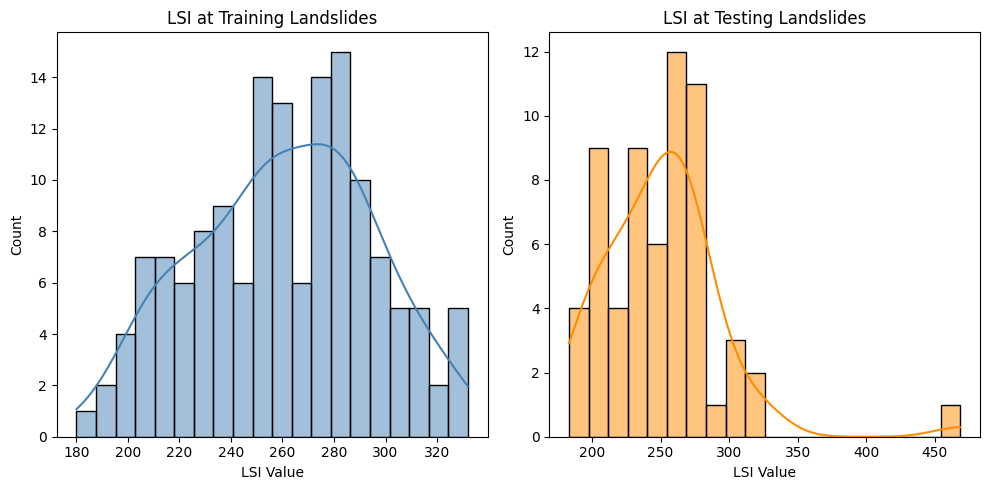

In [17]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
sns.histplot(train_lsi, bins=20, kde=True, color="steelblue")
plt.title("LSI at Training Landslides")
plt.xlabel("LSI Value")

plt.subplot(1, 2, 2)
sns.histplot(test_lsi, bins=20, kde=True, color="darkorange")
plt.title("LSI at Testing Landslides")
plt.xlabel("LSI Value")

plt.tight_layout()
plt.show()

In [18]:
# Note: Proper ROC needs both landslide and non-landslide samples.
# Here we show the distribution and prepare for future improvement.

print("Version 1: Presence-only analysis")
print("For full ROC/AUC we will add non-landslide background points in Version 2.")

Version 1: Presence-only analysis
For full ROC/AUC we will add non-landslide background points in Version 2.


In [19]:
with rasterio.open(CLASSIFIED_PATH) as src:
    classified = src.read(1)
    nodata = src.nodata

# Count pixels in each class
unique, counts = np.unique(classified[classified != nodata], return_counts=True)

print("Classified Map - Pixel Count per Class:")
for u, c in zip(unique, counts):
    print(f"  Class {u}: {c} pixels")

Classified Map - Pixel Count per Class:
  Class 47: 1 pixels
  Class 48: 15 pixels
  Class 49: 8 pixels
  Class 50: 165 pixels
  Class 51: 155 pixels
  Class 52: 804 pixels
  Class 53: 1538 pixels
  Class 54: 1945 pixels
  Class 55: 3706 pixels
  Class 56: 2642 pixels
  Class 57: 3456 pixels
  Class 58: 4928 pixels
  Class 59: 5937 pixels
  Class 60: 8739 pixels
  Class 61: 11402 pixels
  Class 62: 10686 pixels
  Class 63: 12445 pixels
  Class 64: 16642 pixels
  Class 65: 16790 pixels
  Class 66: 21585 pixels
  Class 67: 22672 pixels
  Class 68: 20461 pixels
  Class 69: 23199 pixels
  Class 70: 25388 pixels
  Class 71: 31183 pixels
  Class 72: 31438 pixels
  Class 73: 28709 pixels
  Class 74: 28896 pixels
  Class 75: 34564 pixels
  Class 76: 43652 pixels
  Class 77: 37396 pixels
  Class 78: 36352 pixels
  Class 79: 38785 pixels
  Class 80: 43555 pixels
  Class 81: 48178 pixels
  Class 82: 47269 pixels
  Class 83: 47596 pixels
  Class 84: 42480 pixels
  Class 85: 57084 pixels
  Class 86

## Summary – Version 1

- Successfully loaded existing LSI and Classified results from ArcGIS
- Extracted LSI values at Training and Testing landslide locations
- Visualized the distribution of susceptibility values at known landslides
- Prepared the structure for future improvements

### Next Improvements (Version 2)
- Add non-landslide sampling for proper ROC curve and AUC calculation
- Fully re-implement Frequency Ratio calculation in pure Python
- Automatic matching of FR table with factor rasters